In [190]:
import numpy as np
import pandas as pd
import csv
import seaborn as sns
sns.__version__
import tensorflow as tf
tf.__version__
import matplotlib.pyplot as plt
%matplotlib inline

In [191]:
!pip install keras
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from keras.layers import Dense,Activation,Dropout
!pip install keras scikit-learn

In [192]:
df=pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


## Check Mising Value

In [193]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
diabetes,0


In [194]:
df.duplicated().sum()


np.int64(0)

Informasi of Dataset

In [195]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   diabetes                  768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Cheking Imbslsnced Dstsdet

In [196]:
df.diabetes.value_counts()

,count
diabetes,
0,500
1,268


## Train-Test Split

In [197]:
X = df.drop(columns='diabetes')
y = df.diabetes

In [198]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

In [199]:
from tensorflow.keras.utils import to_categorical

# Konversi label menjadi one-hot encoding
y_train = to_categorical(y_train, num_classes=2)
y_test = to_categorical(y_test, num_classes=2)
y_val = to_categorical(y_val, num_classes=2)


In [200]:
y_test

array([[0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.

In [201]:
X_train.shape, X_test.shape, X_val.shape, y_train.shape, y_test.shape,  y_val.shape

((621, 8), (77, 8), (70, 8), (621, 2), (77, 2), (70, 2))

## Scalling

In [202]:
X_train.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

In [203]:
from sklearn.preprocessing import StandardScaler
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']

scaler = StandardScaler()
X_train[columns] = scaler.fit_transform(X_train[columns])
X_val[columns] = scaler.transform(X_val[columns])
X_test[columns] = scaler.transform(X_test[columns])

In [204]:
from tensorflow.keras.models import Sequential

In [205]:
!pip install tensorflow

In [206]:
from tensorflow.keras.layers import Dense


In [207]:
model = Sequential()
model.add(Dense(units=16,activation='relu', input_shape=(8,))) #input layer
model.add(Dense(units = 16,activation='relu')) #hidden # sunction activation = relu (leaky relu, dll), sigmoid, tanh, softmax
model.add(Dense(units = 64,activation='relu')) #hidden
model.add(Dense(units = 32,activation='relu')) #hidden
model.add(Dense(2,activation='softmax')) # gunakan softmax: output > 1,
                                         # gunakan sigmoid: output = 1
model.compile(loss ='categorical_crossentropy',optimizer='adam',metrics=['accuracy']) #  optimizer='adam', SGD, Adamax
model.summary() # loss ='categorical_crossentropy', sparse_categorical_crossendtropy

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,650 (14.26 KB)

 Trainable params: 3,650 (14.26 KB)

 Non-trainable params: 0 (0.00 B)

## Training Model

In [208]:
!pip install tensorflow

In [209]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=1000, batch_size=64, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.5362 - loss: 0.6945 - val_accuracy: 0.6429 - val_loss: 0.6654
Epoch 2/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6602 - loss: 0.6565 - val_accuracy: 0.6571 - val_loss: 0.6437
Epoch 3/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6602 - loss: 0.6304 - val_accuracy: 0.6857 - val_loss: 0.6146
Epoch 4/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6989 - loss: 0.5954 - val_accuracy: 0.7286 - val_loss: 0.5773
Epoch 5/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7246 - loss: 0.5581 - val_accuracy: 0.7857 - val_loss: 0.5324
Epoch 6/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7424 - loss: 0.5205 - val_accuracy: 0.8000 - val_loss: 0.4935
Epoch 7/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7568 - loss: 0.4924 - val_accuracy: 0.8429 - val_loss: 0.4661
Epoch 8/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7681 - loss: 0.4770 - val_accu

## Evaluasi Model

In [210]:
evaluation = model.evaluate(X_test, y_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8312 - loss: 0.4397


## Visualisasi

### Loss

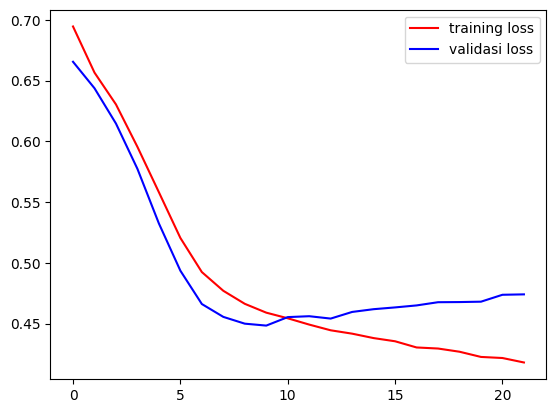

In [211]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(loss,'r', label = 'training loss')
plt.plot(val_loss,'b', label = 'validasi loss')
plt.legend()

### Accurasy

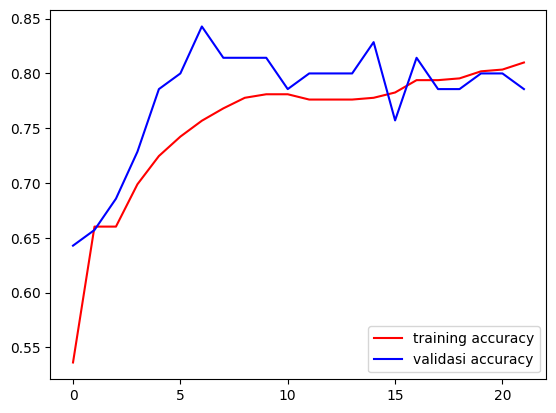

In [212]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.plot(acc,'r', label = 'training accuracy')
plt.plot(val_acc,'b', label = 'validasi accuracy')
plt.legend()

In [213]:
y_pred = np.argmax(model.predict(X_test),axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


In [214]:
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [215]:
y_test = np.argmax(y_test,axis=1)
y_test

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0])

In [216]:
print ('accuracy_score: ',accuracy_score(y_test,y_pred))

accuracy_score:  0.8311688311688312


In [217]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[46,  5],
       [ 8, 18]])

Text(0.5, 1.0, 'Confusion Matrix Model with Artificial Neural Network')

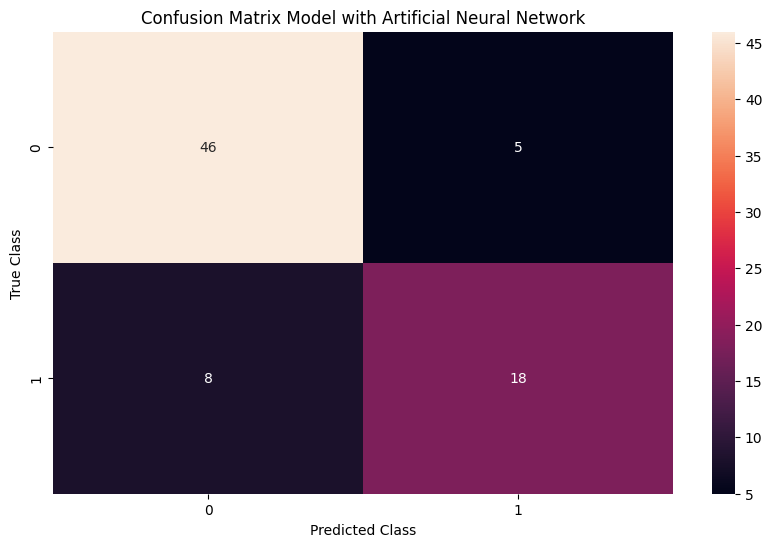

In [218]:
fig = plt.figure(figsize = (10, 6))
sns.heatmap(cm, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model with Artificial Neural Network")